In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
from sklearn.inspection import permutation_importance
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shutil
from src.mass_detect.note.config import LNDB_DIR, PATCHES_DIR, READER_RATINGS_FILE, REPO_ROOT
from src.mass_detect.note.lidc import save_lidc_reader_ratings
from src.mass_detect.note.models import HarmonisedModel, NoduleMalignancyModel, RidgeWithTunedCuts, batch_of, make_size_model, size_target
from src.mass_detect.note.validation import all_metrics, check_submission, competition_metrics, grouped_cv_predictions, paired_difference, summarise

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Model, Validation, Submission
  </h1>
</div>

The classes and functions live in `src/mass_detect/note/models.py` (models, size model, ComBat) and `src/mass_detect/note/validation.py` (metrics, grouped cross validation, submission check).

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    Project code - Model
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Ordinal Logistic Regression
  </h3>
  <p>
    We chose this model because the malignancy ratings 1 to 5 are ordered, and the competition scores errors by their distance (QWK and MAE). Moreover, taking into consideration the CRISP-DM Methodology we followed, the Business Understanding phase also highlights the difference between mistaking a 1 for a 2 or a 1 for a 5 in a clinical environment. 
  </p>
  <p>
P(rating &le; k) = sigmoid(cut<sub>k</sub> - x &middot; w),
k = 1, 2, 3, 4,
with
cut<sub>1</sub> &lt; cut<sub>2</sub> &lt; cut<sub>3</sub> &lt; cut<sub>4</sub>.
</p>
<p>
P(rating = k) =
P(rating &le; k) -
P(rating &le; k - 1).
</p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Regularization
  </h3>
  <p>
  We add an L2 penalty alpha/2 * |w|^2 on the weights (not on the cut points), as in ridge logistic regression (le Cessie and van Houwelingen, 1992). It keeps the weights stable when features are correlated, which is the case for size and intensity features.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Decision Rule
  </h3>
    <p>
The model gives a probability for each of the five classes however we must return a single number. This specific choice will have to definitly be related to the error we consider the most important to minimise.
The most probable class (argmax) is right most often, which is optimal for accuracy. The median of the distribution, the first class where the cumulative probability reaches 0.5, keeps the error small when the prediction is wrong, which is optimal for the mean absolute error. The two usually agree. They differ when the probability is spread out: with probabilities 0.35, 0.10, 0.15, 0.20 and 0.20 for instance argmax picks class 1 while the median picks class 3, which has a lower expected absolute error (1.4 against 1.8). At the end we choose the argmax but we may test otherwise later.
</p>
<p>
In the final model the probabilities are first corrected for class frequencies (τ = 0.5) so that the rare classes 4 and 5 are not ignored. The four cut points must stay in increasing order, or some class would get a negative probability. The optimiser therefore learns the first cut point and three steps written as exponentials, which are always positive, so every cut point lies to the right of the previous one.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    The malignancy model, the v1 baseline and a correlation filter
  </h3>
  <p>
    Focusing on the idea that size is the strongest single predictor of malignancy and the basis of the clinical guidelines, as we have already read in multiple studies (Lung-RADS; MacMahon et al., 2017), we have a problem: the radiologists' diameter exists in the training data but not in the test file. Therefore we had to create our own. However, our segmentation measures it poorly: its equivalent diameter has a Spearman correlation of only 0.65 with the radiologists' diameter.
  </p>
  <p>As the diameter information is not given in the test set we cannot use it as model's input. Therefore the solution we found was to use it as target and not as an input:</p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">We train an auxiliar model that learns how to predict the diameter that the radiologists would have identified. This model uses the patch features (that exist both in training and testing) to predict such diameter.</li>
    <li style="margin-bottom: 8px;">The predicted size comes on in the model as a feature.</li> 
    <li style="margin-bottom: 8px;">In the test set the auxiliar model is able to predict the diameter from the patch.</li>
</ol>
<p>
The idea of using information that is available only during training is the idea of learning using privileged information (Vapnik and Vashist, 2009).
  </p>
  <p><strong>Two important details:</strong></p>
<ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">It predicts the log of the diameter and not the diameter itself. We decided this part since in this context the gravity of an error is relative. For instance, commiting an error of 1mm in a 4mm nodule is far worse than commiting an error of 1mm in a 25mm nodule. Using the mathematical log the error is therefore relative.</li>
    <li style="margin-bottom: 8px;">In the training data, the nodule's size that is predicted uses the "out-of-fold" idea.</li> 
</ol>
<p>
If the ordinal model were trained on size predictions that the size model made on its own training rows, those predictions would be too good, and the ordinal model would trust them more than it should at test time. So, inside fit(), the size of each training row is predicted by a size model that did not see that row's CT (grouped folds), which is the usual way to stack models (Wolpert, 1992). At predict time the size model trained on all training rows is used. 
</p>
<p>
Everything happens inside fit(), so cross validation stays honest: the size model, the imputer, the scaler and the ordinal model only ever see the training part of each fold.
</p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    ComBat harmonisation with a reference batch
  </h3>
  <p>
    The same nodule scanned with another scanner, kernel or slice thickness gives different feature values (Shafiq-ul-Hassan et al., 2017). LIDC mixes GE, Siemens, Philips and Toshiba scanners with slices up to 5 mm, while LNDb, and therefore the test set, comes from Siemens scanners with 1 mm slices.
    Training on LIDC features as they are could teach the model relations that do not hold in LNDb.
  </p>
  <p>
    ComBat (Johnson et al., 2007) models each feature as feature = mean + effect of the biological covariates + batch shift + batch scale * noiseand removes the batch shift and scale. It is the most used harmonisation method in radiomics (Orlhac et al., 2022; Mahon et al., 2020). We use two of its variants:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">a reference batch (Zhang et al., 2018): LNDb is the reference and is never changed, and only the LIDC rows are moved towards it. Since the test set is LNDb, test features need no adjustment at all.</li>
    <li style="margin-bottom: 8px;">biological covariates: the malignancy rating is kept in the model, so that the difference between a benign LIDC nodule and a malignant one is not removed as if it were a scanner effect (Orlhac et al., 2022). Using the label here is safe because only LIDC training rows are changed; the LNDb rows used for validation are never touched.</li>
  </ol>
  <p>
    Batches: LNDb (reference) and one batch per LIDC manufacturer.
  </p>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Metrics, Grouped Cross Validation
  </h3>
  <p>
    Competition metrics: balanced accuracy, macro F1, quadratic weighted kappa and mean absolute error (MAE). 
  </p>
  <p>
    Extra metrics, used only for our own decisions and for the report:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">composite = BA + F1 + QWK - MAE. The ranking rewards being good on all four at once.</li>
    <li style="margin-bottom: 8px;">within_one: share of predictions at most one class away. Common in ordinal problems, and it is what a reader would call "almost right" (Gaudette and Japkowicz, 2009, discuss ordinal evaluation measures).</li>
    <li style="margin-bottom: 8px;">recall of each class and sensitivity for ratings 4 and 5, the clinically importan nodules.</li>
  </ul>
  <p>
    Validation design:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Grouped by CT (LNDb) or patient (LIDC): nodules of one scan share scanner, protocol and anatomy, so splitting them would leak information as we have previously discussed.</li>
    <li style="margin-bottom: 8px;">Repeated with different seeds: with a few hundred nodules a single split has wide error bars (Varoquaux, 2018).</li>
    <li style="margin-bottom: 8px;">95% intervals by resampling whole CTs (cluster bootstrap, Field and Welsh, 2007), because nodules of the same CT are not independent.</li>
  </ul>
</div>

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Testing the model, the harmonization and the submission check, on small synthetic data. Each test has a known answer, so it can fail.
  </p>
</div> 

In [3]:
from src.mass_detect.tests.test_models import *   # noqa: the unit tests live in src/mass_detect/tests/test_models.py
tests = [value for name, value in globals().items() if name.startswith("test_") and callable(value)]
for test in tests:
    test()
    print("passed:", test.__name__)
print(f"{len(tests)} tests passed")

passed: test_probabilities_are_valid
passed: test_recovers_the_true_weights_and_cut_points
passed: test_cut_points_stay_in_order
passed: test_median_and_argmax_are_classes
passed: test_combat_leaves_the_reference_untouched_and_removes_a_shift
passed: test_metrics_of_a_perfect_prediction
passed: test_check_submission_catches_wrong_files
7 tests passed


In [4]:
pd.set_option("display.width", 160)
REPEATS = 3          # 3 x 5 folds per model: enough to rank models, and this part runs in about 20 minutes

# Individual LIDC ratings for the agreement ceiling (needs pylidc; src/mass_detect/note/lidc.py), if not on disk yet
if not READER_RATINGS_FILE.exists():
    save_lidc_reader_ratings()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The data
  </h3>
  <p>
  One row per nodule with a malignancy rating, from LNDb and LIDC-IDRI with the features of its patch.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Only nodules are used - non nodules have no rating and would only add noise. LNDb nodules smaller than 3 mm are nodules with a rating, so they stay. </li>
    <li style="margin-bottom: 8px;">The label is the mean of the radiologists' ratings rounded half up (2.5 becomes 3). </li>
    <li style="margin-bottom: 8px;">LIDC rows are kept only when the position of the nodule was confirmed by two independent computations as previously stated.</li>
    <li style="margin-bottom: 8px;">'size_target' is the log of the radiologists' equivalent diameter (2.5 mm for nodules under 3 mm, which have no segmentation). It is only used as a training target.</li>
    <li style="margin-bottom: 8px;">'group' is the patient, so that all nodules of a CT stay on the same side of every split.</p>
  </ul>
</div>

In [5]:
def lndb_patch_id(nodule_uid):
    ct, finding = nodule_uid.rsplit("_", 1)
    return f"{ct}_f{int(finding):03d}"

table = pd.read_csv("nodule_table.csv")
features = pd.read_csv(PATCHES_DIR / "features.csv")
lidc_manifest = pd.read_csv(PATCHES_DIR / "manifest_lidc.csv")

nodules = table[(table.is_nodule == 1) & table.mal_mean.notna()].copy()
nodules["patch_id"] = [lndb_patch_id(u) if d == "LNDb" else u for u, d in zip(nodules.nodule_uid, nodules.dataset)]
nodules = nodules.rename(columns={"diameter_mm": "radiologist_diameter_mm"}).drop(columns="volume_mm3")
data = nodules.merge(features.drop(columns="split"), on="patch_id")
verified = lidc_manifest.loc[lidc_manifest.position_verified, "patch_id"]
data = data[(data.dataset == "LNDb") | data.patch_id.isin(verified)].reset_index(drop=True)

data["rating"] = np.floor(data.mal_mean + 0.5).astype(int)
data["size_target"] = size_target(data.radiologist_diameter_mm)
data["group"] = data.patient_id
data["batch"] = batch_of(data.dataset.values, data.manufacturer.values)
data["is_lidc"] = (data.dataset == "LIDC").astype(int)

HANDCRAFTED = ["centre_hu", "lung_hu", "threshold_hu", "volume_mm3", "diameter_mm", "max_extent_mm", "elongation",
               "flatness", "sphericity", "hu_mean", "hu_std", "hu_p10", "hu_p50", "hu_p90", "hu_skew", "solid_fraction",
               "ground_glass_fraction", "edge_gradient", "ring_mean_hu", "ring_solid_fraction", "contrast_hu"]
SPHERE = [c for c in features.columns if c.startswith("sphere")]
FEATURES = HANDCRAFTED + SPHERE

is_lndb = (data.dataset == "LNDb").to_numpy()
lndb = data[is_lndb].reset_index(drop=True)
y, groups = lndb.rating.to_numpy(), lndb.group.to_numpy()
print(data.groupby("dataset").size().to_dict(), "| features:", len(FEATURES))
print("LNDb classes:", lndb.rating.value_counts().sort_index().to_dict())

{'LIDC': 2621, 'LNDb': 765} | features: 30
LNDb classes: {1: 213, 2: 254, 3: 209, 4: 71, 5: 18}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Validation and measurements
  </h3>
  <p>
  The competition metrics are: Balanced accuracy, macro F1, QWK and MAE. They pull in different directions: balanced accuracy and macro F1 give each class the same weight, so they reward getting the rare classes 4 and 5 right; QWK and MAE reward being close, which favours predictions near the centre.
  </p>
  <p>
  We'll consider extra metrics for our own decisions:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">'composite = BA + F1 + QWK - MAE'. The ranking is the mean rank over the four metrics. </li>
    <li style="margin-bottom: 8px;">'within_one' (share of predictions at most one class away) and 'sensitivity_4_5' (share of nodules rated 4 or 5 that are predicted 4 or 5), which are easier to read clinically.</li>
  </ul>
  <p>
  Regarding the design... Folds grouped by patient and stratified by class (StratifiedGroupKFold), repeated with different seeds, because with 765 nodules one split has wide error bars (Varoquaux, 2018). Intervals come from resampling whole CTs (cluster bootstrap, Field and Welsh, 2007). When LIDC is used it is always on the training side; only LNDb nodules are ever validated, because the test set is LNDb.
  </p>
  <p>
  A model trained on radiologists' ratings cannot be expected to agree with them better than they agree with each other. We measure the agreement between two radiologists on the same nodule, for LNDb and for LIDC. 
  </p>
</div>

In [6]:
def pairwise_agreement(ratings_by_nodule):
    # every pair of radiologists that rated the same nodule
    first, second = [], []
    for ratings in ratings_by_nodule:
        for i in range(len(ratings)):
            for j in range(i + 1, len(ratings)):
                first.append(ratings[i]); second.append(ratings[j])
    return pd.Series(competition_metrics(np.array(first), np.array(second))).round(3), len(first)

# LNDb: readings (trainNodules.csv) and their malignancy (chars_trainNodules.csv) are in the same row order (notebook explorar_lndb)
readings = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules.csv")
readings["malignancy"] = pd.read_csv(LNDB_DIR / "data" / "chars_trainNodules.csv")["malignancy"].values
merged = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainNodules_gt.csv")
lookup = readings.set_index(["LNDbID", "RadID", "FindingID"])["malignancy"]
lndb_ratings = []
for row in merged[merged.RadID.astype(str).str.contains(",")].itertuples():
    values = [lookup[(row.LNDbID, int(r), int(f))] for r, f in zip(str(row.RadID).split(","), str(row.RadFindingID).split(","))]
    values = [int(v) for v in values if v > 0]            # 0 means "not filled in"
    if len(values) >= 2:
        lndb_ratings.append(values)

lidc_ratings = pd.read_csv(PATCHES_DIR / "lidc_reader_ratings.csv").groupby("nodule").malignancy.apply(list)
lidc_ratings = [r for r in lidc_ratings if len(r) >= 2]

ceiling = {}
for name, ratings in (("LNDb", lndb_ratings), ("LIDC", lidc_ratings)):
    scores, n_pairs = pairwise_agreement(ratings)
    ceiling[f"{name}: radiologist vs radiologist ({n_pairs} pairs)"] = scores
pd.DataFrame(ceiling).T

,balanced_accuracy,macro_f1,qwk,mae
LNDb: radiologist vs radiologist (309 pairs),0.445,0.411,0.527,0.790
LIDC: radiologist vs radiologist (7313 pairs),0.384,0.390,0.466,0.884


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  Two radiologists of the same hospital agree with QWK of about 0.53 and differ by almost 0.8 classes on average; in LIDC the agreement is lower. This is the noise level of our labels and the reason why no model will get close to perfect scores. 
  </p>
</div>

In [7]:
results, oof = {}, {}

def evaluate(name, make_model, use_lidc=False, repeats=REPEATS, first_seed=0):
    # LNDb only, or LNDb + LIDC with LIDC always in training. Only LNDb nodules are validated.
    if use_lidc:
        predictions = grouped_cv_predictions(make_model, data, data.rating.to_numpy(), data.group.to_numpy(),
                                             repeats, evaluate_mask=is_lndb, first_seed=first_seed)
        predictions = [p[is_lndb] for p in predictions]
    else:
        predictions = grouped_cv_predictions(make_model, lndb, y, groups, repeats, first_seed=first_seed)
    oof[name] = predictions
    results[name] = summarise(y, groups, predictions)["mean"]
    return results[name]

oof["constant 2"] = [np.full(len(y), 2)]
results["constant 2"] = summarise(y, groups, oof["constant 2"])["mean"]
evaluate("v1: ridge + tuned cuts", lambda: RidgeWithTunedCuts(HANDCRAFTED))
evaluate("ordinal", lambda: NoduleMalignancyModel(HANDCRAFTED))
evaluate("ordinal + size", lambda: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES))
pd.DataFrame(results).T

,balanced_accuracy,macro_f1,qwk,mae,composite
constant 2,0.200,0.100,0.000,0.808,-0.508
v1: ridge + tuned cuts,0.409,0.395,0.513,0.716,0.601
ordinal,0.378,0.410,0.510,0.627,0.671
ordinal + size,0.375,0.403,0.518,0.619,0.678


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
  The ordinal model lowers the MAE by about 0.09 class compared with v1 at the same QWK, because it keeps predictions close to where the probability mass is, while the tuned cut points of v1 push predictions outwards to win balanced accuracy. It loses some balanced accuracy, which section 5 recovers. Adding the learned size raises QWK and lowers MAE a little.
  </p>
  <p>
  How good is the learned size? On LNDb nodules with a segmentation, the Spearman correlation with the radiologists' diameter is shown below for our automatic segmentation and for the size model (out of fold, grouped by CT).
  </p>
</div>

In [8]:
def size_quality(extra_rows=None):
    predicted = np.zeros(len(lndb))
    for train, test in GroupKFold(5).split(lndb, y, groups):
        rows = lndb.iloc[train] if extra_rows is None else pd.concat([lndb.iloc[train], extra_rows])
        predicted[test] = make_size_model().fit(rows[FEATURES], rows.size_target).predict(lndb.iloc[test][FEATURES])
    measured = lndb.radiologist_diameter_mm.notna()
    return pd.Series(predicted[measured]).corr(lndb.radiologist_diameter_mm[measured].reset_index(drop=True), method="spearman")

measured = lndb.radiologist_diameter_mm.notna()
print(f"automatic segmentation:     {lndb.loc[measured, ['diameter_mm', 'radiologist_diameter_mm']].corr('spearman').iloc[0, 1]:.3f}")
print(f"size model, LNDb only:      {size_quality():.3f}")
print(f"size model, LNDb + LIDC:    {size_quality(data[~is_lndb]):.3f}")

automatic segmentation:     0.648
size model, LNDb only:      0.828
size model, LNDb + LIDC:    0.859


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Using LIDC
  </h3>
  <p>
  LIDC has 2621 usable nodules, more than three times LNDb, and many more in classes 4 and 5. We tried four ways of using it, always validating on LNDb only:
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">LIDC in the classifier, as it is.</li>
    <li style="margin-bottom: 8px;">The same with a dataset indicator ('is_lidc'), so that the model can learn a different label level for LIDC and use the LNDb level at test time (a simple form of domain adaptation).</li>
    <li style="margin-bottom: 8px;">LIDC in the classifier after ComBat harmonisation towards LNDb ('src/mass_detect/harmonization.py'): reference batch LNDb, one batch per LIDC manufacturer, malignancy kept as biological covariate (Johnson et al., 2007; Zhang et al., 2018; Orlhac et al., 2022).</li>
    <li style="margin-bottom: 8px;">LIDC only in the size model. The size model learns a physical quantity (the radiologists' diameter), which means the same in both datasets; the classifier learns the subjective rating from LNDb only.</li>
  </ol>
</div>

In [ ]:
evaluate("LIDC in classifier", lambda: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES), use_lidc=True)
evaluate("LIDC in classifier + indicator", lambda: NoduleMalignancyModel(FEATURES + ["is_lidc"], size_inputs=FEATURES), use_lidc=True)
evaluate("LIDC in classifier + ComBat", lambda: HarmonisedModel(NoduleMalignancyModel(FEATURES, size_inputs=FEATURES), FEATURES), use_lidc=True)
evaluate("LIDC in size model only", lambda: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES, size_only_column="is_lidc"), use_lidc=True)
pd.DataFrame(results).T.iloc[-5:]

In [ ]:
reference = oof["ordinal + size"]
for name in ["LIDC in classifier", "LIDC in classifier + indicator", "LIDC in classifier + ComBat", "LIDC in size model only"]:
    print(f"{name:32s} composite minus 'ordinal + size':", paired_difference(y, groups, reference, oof[name]))

LIDC in classifier               composite minus 'ordinal + size': {'difference': np.float64(-0.179), 'ci_low': np.float64(-0.364), 'ci_high': np.float64(-0.01)}
LIDC in classifier + indicator   composite minus 'ordinal + size': {'difference': np.float64(-0.237), 'ci_low': np.float64(-0.424), 'ci_high': np.float64(-0.038)}
LIDC in classifier + ComBat      composite minus 'ordinal + size': {'difference': np.float64(-0.266), 'ci_low': np.float64(-0.423), 'ci_high': np.float64(-0.106)}
LIDC in size model only          composite minus 'ordinal + size': {'difference': np.float64(0.007), 'ci_low': np.float64(-0.061), 'ci_high': np.float64(0.088)}


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
    LIDC trains the size model only. The likely reasons are understandable from what we have already explored: LIDC labels are means of up to four readers who read in two phases, so 47% of LIDC nodules land on class 3 against 27% in LNDb, and the relation between the features and the rating is not the same. ComBat corrects the scanner effect on the features (Orlhac et al., 2022), but it cannot correct a different labelling culture. Using LIDC for the size model is different: the diameter of a segmentation means the same thing in both datasets, and the size model indeed predicts LNDb sizes better with LIDC (previous section). We report the failed attempts too, because a negative result is part of the evidence.
</p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The decision rule
  </h3>
  <p>
The ordinal model gives a probability for each class. But with imbalanced classes the argmax rarely predicts the rare classes 4 and 5, which costs balanced accuracy and macro F1. Dividing each probability by the training share of its class raised to a power τ moves predictions towards the rare classes (Saerens et al., 2002): τ = 0 is the plain argmax, τ = 1 treats all classes as equally frequent. We fixed <strong>τ = 0.5</strong> as the compromise before looking at the alternatives, and show the others only to understand the trade off. We'll confirm the choice on folds that were not used here.
  </p>
</div>

In [ ]:
for tau in (0.0, 0.25, 0.5, 0.75, 1.0):
    evaluate(f"final model, tau={tau}",
             lambda tau=tau: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES, size_only_column="is_lidc", prior_power=tau),
             use_lidc=True)
trade_off = pd.DataFrame(results).T.loc[[f"final model, tau={t}" for t in (0.0, 0.25, 0.5, 0.75, 1.0)]]
trade_off

,balanced_accuracy,macro_f1,qwk,mae,composite
"final model, tau=0.0",0.388,0.421,0.508,0.626,0.692
"final model, tau=0.25",0.410,0.444,0.530,0.627,0.758
"final model, tau=0.5",0.420,0.443,0.530,0.650,0.743
"final model, tau=0.75",0.433,0.435,0.526,0.678,0.716
"final model, tau=1.0",0.432,0.399,0.522,0.733,0.620


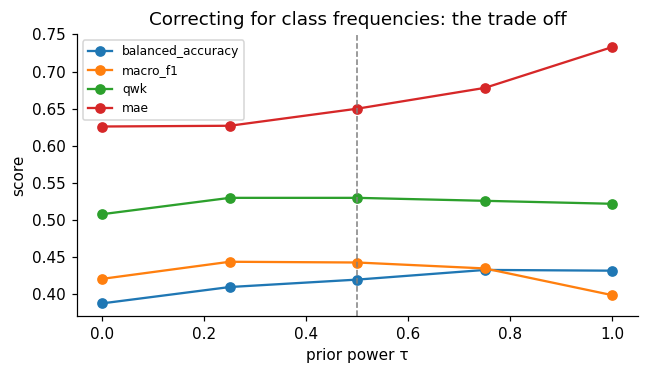

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
taus = [0.0, 0.25, 0.5, 0.75, 1.0]
for metric in ("balanced_accuracy", "macro_f1", "qwk", "mae"):
    ax.plot(taus, trade_off[metric].values, marker="o", label=metric)
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set(xlabel="prior power τ", ylabel="score", title="Correcting for class frequencies: the trade off")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<p>
As τ grows, balanced accuracy rises and MAE gets worse; macro F1 and QWK are flat between 0.25 and 0.5 and drop at 1.
</p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Confirmation on folds that were not used to choose
  </h3>
  <p>
  Choosing among several variants on the same folds used to report them is optimistic (Cawley and Talbot, 2010). We therefore evaluate v1 and the final model again (a) on five new repetitions with seeds never used above, and (b) on the four official folds distributed with LNDb (`trainFolds.csv`, split by CT), which played no part in any decision.
  </p>
  <p>
We'll see that, on the official folds, the final model is better than v1 on all four metrics.
</p>
</div>

In [ ]:
make_final = lambda: NoduleMalignancyModel(FEATURES, size_inputs=FEATURES, size_only_column="is_lidc", prior_power=0.5)
make_v1 = lambda: RidgeWithTunedCuts(HANDCRAFTED)

confirm = {}
confirm["v1 (new seeds)"] = evaluate("v1, new seeds", make_v1, repeats=5, first_seed=100)
confirm["final (new seeds)"] = evaluate("final, new seeds", make_final, use_lidc=True, repeats=5, first_seed=100)
print("composite, final minus v1 (new seeds):", paired_difference(y, groups, oof["v1, new seeds"], oof["final, new seeds"]))

official = pd.read_csv(LNDB_DIR / "LNDb_csvs" / "trainFolds.csv")
def official_fold_predictions(make_model, use_lidc):
    predicted = np.zeros(len(lndb), dtype=int)
    for column in official.columns:
        test_scans = official[column].dropna().astype(int).map("LNDb-{:04d}".format)
        is_test = lndb.scan_id.isin(test_scans).to_numpy()
        train = pd.concat([lndb[~is_test], data[~is_lndb]]) if use_lidc else lndb[~is_test]
        predicted[is_test] = make_model().fit(train, train.rating.to_numpy()).predict(lndb[is_test])
    return [predicted]
confirm["v1 (official folds)"] = summarise(y, groups, official_fold_predictions(make_v1, False))["mean"]
confirm["final (official folds)"] = summarise(y, groups, official_fold_predictions(make_final, True))["mean"]
pd.DataFrame(confirm).T

composite, final minus v1 (new seeds): {'difference': np.float64(0.07), 'ci_low': np.float64(-0.059), 'ci_high': np.float64(0.2)}


,balanced_accuracy,macro_f1,qwk,mae,composite
v1 (new seeds),0.431,0.405,0.517,0.722,0.631
final (new seeds),0.404,0.425,0.526,0.653,0.702
v1 (official folds),0.398,0.384,0.519,0.714,0.587
final (official folds),0.411,0.429,0.533,0.654,0.720


In [ ]:
final_oof = oof["final, new seeds"]
rng = np.random.default_rng(0)
draws = []
for _ in range(3000):
    rows = rng.choice(len(y), 55, replace=False)
    draws.append(competition_metrics(y[rows], final_oof[rng.integers(len(final_oof))][rows]))
draws = pd.DataFrame(draws)
draws.describe(percentiles=[0.025, 0.975]).loc[["mean", "std", "2.5%", "97.5%"]].round(3)

,balanced_accuracy,macro_f1,qwk,mae
mean,0.411,0.401,0.511,0.656
std,0.089,0.090,0.109,0.092
2.5%,0.258,0.252,0.281,0.473
97.5%,0.601,0.596,0.704,0.836


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Errors, subgroups, and what the model looks at
  </h3>
</div>

In [ ]:
prediction = final_oof[0]
print("Confusion matrix (rows: true rating 1..5, columns: predicted 1..5)")
print(confusion_matrix(y, prediction, labels=range(1, 6)))
extra = pd.Series(all_metrics(y, prediction)).round(3)
extra[["within_one", "sensitivity_4_5", "recall_1", "recall_2", "recall_3", "recall_4", "recall_5"]]

Confusion matrix (rows: true rating 1..5, columns: predicted 1..5)
[[122  68  19   4   0]
 [ 45 138  56  14   1]
 [ 20  89  79  21   0]
 [  4  13  30  24   0]
 [  0   3   4   7   4]]


within_one         0.893
sensitivity_4_5    0.393
recall_1           0.573
recall_2           0.543
recall_3           0.378
recall_4           0.338
recall_5           0.222
dtype: float64

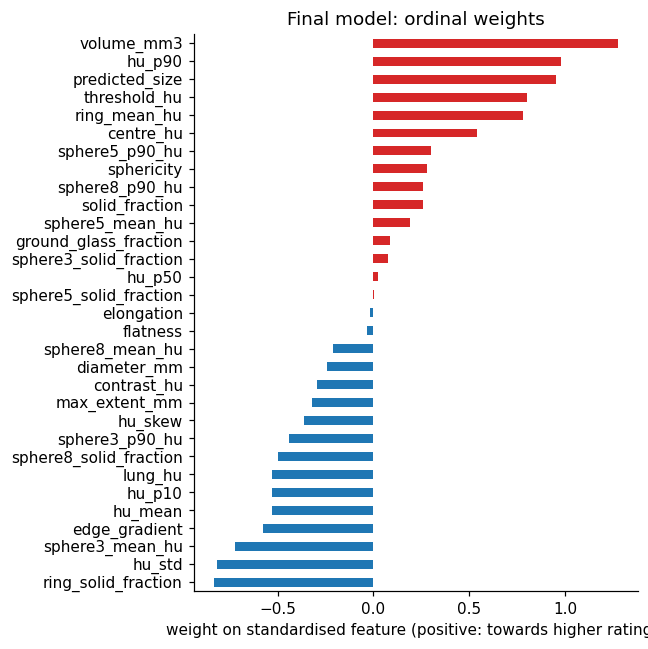

In [ ]:
final_model = make_final().fit(data, data.rating.to_numpy())
ordinal = final_model.model_.named_steps["ordinallogisticregression"]
weights = pd.Series(ordinal.coef_, index=FEATURES + ["predicted_size"]).sort_values()
fig, ax = plt.subplots(figsize=(6, 6))
weights.plot.barh(ax=ax, color=["tab:blue" if w < 0 else "tab:red" for w in weights])
ax.set(xlabel="weight on standardised feature (positive: towards higher ratings)", title="Final model: ordinal weights")
plt.tight_layout(); plt.show()

In [ ]:
# Permutation importance: how much the composite drops when one feature is shuffled in held out folds
composite_scorer = lambda model, X, target: all_metrics(target, model.predict(X))["composite"]
importances = []
for train, test in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(lndb, y, groups):
    rows = pd.concat([lndb.iloc[train], data[~is_lndb]])
    model = make_final().fit(rows, rows.rating.to_numpy())
    result = permutation_importance(model, lndb.iloc[test][FEATURES], y[test], scoring=composite_scorer, n_repeats=5,
                                    random_state=0)
    importances.append(pd.Series(result.importances_mean, index=FEATURES))
importance = pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False)
importance.head(10).round(3)

volume_mm3             0.509
threshold_hu           0.460
ring_mean_hu           0.409
hu_std                 0.393
ring_solid_fraction    0.358
hu_p90                 0.321
centre_hu              0.296
hu_skew                0.253
lung_hu                0.209
sphere5_mean_hu        0.171
dtype: float64

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The weights and the permutation importance tell the same story: size (the volume of our mask and the predicted size, whose weights share the same information) and the density of the nodule and of its surroundings carry most of the signal, which is what radiologists use (size, solid or ground glass, calcification). Permutation importance is computed on held out folds and with the competition composite, so it measures what each feature contributes to our actual objective (Molnar, 2022, gives a readable account of both methods). Correlated features share their importance, so small values must not be read as "useless".
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   1-to-3 scale for the report
  </h3>
  <p>
    As a complement we decided to also set the ratings to a 1 to 3 scale in order to be more adequate to the clinical procedure. With this results the communication with the clinical body is easier since knowing exactly if a nodule is considered to be Benign or Malign is exactly what they expect to know and to address. Benign (ratings 1 and 2), indeterminate (3) and suspicious (4 and 5).
  </p>
</div>

In [ ]:
to_three = lambda rating: np.digitize(rating, [2.5, 3.5]) + 1
three_true, three_pred = to_three(y), to_three(prediction)
from sklearn.metrics import balanced_accuracy_score, f1_score, mean_absolute_error
pd.Series({"balanced_accuracy": balanced_accuracy_score(three_true, three_pred),
           "macro_f1": f1_score(three_true, three_pred, average="macro"),
           "qwk": cohen_kappa_score(three_true, three_pred, weights="quadratic"),
           "mae": mean_absolute_error(three_true, three_pred)}).round(3)

balanced_accuracy    0.523
macro_f1             0.532
qwk                  0.444
mae                  0.414
dtype: float64

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Submission
  </h3>
  <p>
The final model is trained on all 765 LNDb nodules (classifier and size model) and all 2621 LIDC nodules (size model only), and predicts every test candidate as if it were a nodule. The five candidates of CT 286 whose centre falls outside the scan have no patch; their features are missing and the model fills them with the training medians, like any missing value. 
</p>
</div>

In [ ]:
test_rows = pd.read_csv(LNDB_DIR / "testNodules.csv")
test_rows["patch_id"] = [f"LNDb-{int(c):04d}_f{int(f):03d}" for c, f in zip(test_rows.LNDbID, test_rows.FindingID)]
test = test_rows.merge(features[features.split == "test"].drop(columns="split"), on="patch_id", how="left")
test["is_lidc"], test["batch"] = 0, "LNDb"

submission = test_rows[["LNDbID", "FindingID", "x", "y", "z"]].copy()
submission["prediction"] = final_model.predict(test).astype(int)
check_submission(submission, test_rows)

previous = REPO_ROOT / "reports" / "predictions.csv"
backup = REPO_ROOT / "reports" / "predictions_v1_ridge.csv"
if previous.exists() and not backup.exists():
    shutil.copy(previous, backup)
submission.to_csv(previous, index=False)
print("saved", previous.relative_to(REPO_ROOT), "|", len(submission), "rows")
pd.DataFrame({"training labels (LNDb)": pd.Series(y).value_counts(normalize=True).sort_index(),
              "all test candidates": submission.prediction.value_counts(normalize=True).sort_index(),
              "v1, all test candidates": pd.read_csv(backup).prediction.value_counts(normalize=True).sort_index()}).round(3)

saved reports/predictions.csv | 2900 rows


,training labels (LNDb),all test candidates,"v1, all test candidates"
1,0.278,0.050,0.072
2,0.332,0.293,0.382
3,0.273,0.481,0.221
4,0.093,0.169,0.319
5,0.024,0.006,0.006
